Handling imbalanced data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.utils import resample

upsampling refers to generating more samples of minortiy class to balance the dataset,
downsampling refers to reducing number of samples from majority class to balance the dataset 

In [2]:
n_class_0=900
n_class_1=100

In [3]:
class_0=pd.DataFrame({
    'feature_1':np.random.normal(0,1,900),
    'feature_2':np.random.normal(0,1,900),
    'target':[0]*900
})

In [4]:
class_0.head()

,feature_1,feature_2,target
0,-0.605171,-0.950788,0
1,-1.129319,-0.359249,0
2,1.554168,0.079131,0
3,-1.409516,-0.743062,0
4,-1.365999,0.855955,0


In [5]:
class_1=pd.DataFrame({
    'feature_1':np.random.normal(2,1,100),
    'feature_2':np.random.normal(2,1,100),
    'target':[1]*100
})

In [6]:
class_1.head()

,feature_1,feature_2,target
0,1.116267,0.578030,1
1,2.573782,2.450475,1
2,3.535590,1.605788,1
3,2.930523,2.699306,1
4,2.864707,2.139137,1


In [7]:
class_0.shape,class_1.shape

((900, 3), (100, 3))

In [8]:
df=pd.concat([class_0,class_1],axis=0).reset_index(drop=True)

In [9]:
df.shape

(1000, 3)

In [10]:
df.sample(20)

,feature_1,feature_2,target
161,-1.669774,-0.725208,0
58,0.853971,0.131665,0
885,2.160888,-0.489568,0
765,0.009069,-1.219892,0
445,1.309451,-1.695299,0
112,-1.035166,2.110283,0
156,-1.111586,-0.900914,0
986,2.389463,2.293613,1
381,1.903219,2.444328,0
710,1.114358,-0.621091,0


In [11]:
df['target'].value_counts()

target
0    900
1    100
Name: count, dtype: int64

<Axes: xlabel='feature_1', ylabel='feature_2'>

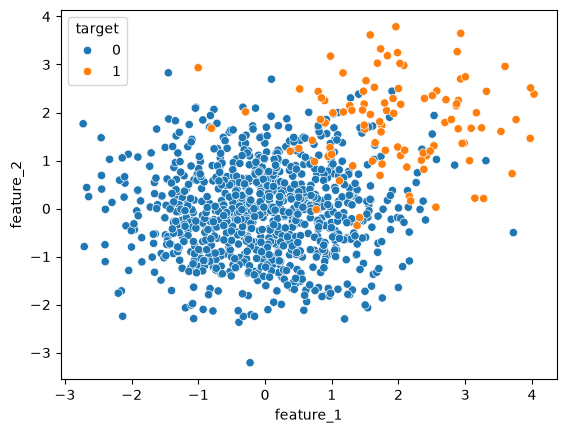

In [12]:
sns.scatterplot(data=df, x='feature_1', y='feature_2', hue='target')

uspampling

In [13]:
df_majority=df[df['target']==0]
df_minority=df[df['target']==1]

In [14]:
df_majority.shape, df_minority.shape

((900, 3), (100, 3))

In [15]:
len(df_majority), len(df_minority)

(900, 100)

In [ ]:
df_minority_upsampled=resample(df_minority,replace=True,n_samples=len(df_majority)) # false bho bhane downsampling

In [17]:
df_minority.shape,df_minority_upsampled.shape

((100, 3), (900, 3))

In [ ]:
df_upsampled=pd.concat([df_majority,df_minority_upsampled],axis=0).reset_index(drop=True)

In [19]:
df_upsampled.shape

(1800, 3)

In [21]:
df_upsampled.sample(20)

,feature_1,feature_2,target
1354,1.733329,3.324699,1
1794,2.162211,0.256639,1
542,-2.726045,1.765989,0
904,1.017970,1.992751,1
662,0.527059,-0.883063,0
364,-0.031934,0.574769,0
1508,2.560267,0.028671,1
948,1.985678,3.247198,1
1081,1.314215,0.889558,1
512,0.833115,-1.330355,0


In [22]:
df_upsampled['target'].value_counts()

target
0    900
1    900
Name: count, dtype: int64

<Axes: xlabel='feature_1', ylabel='feature_2'>

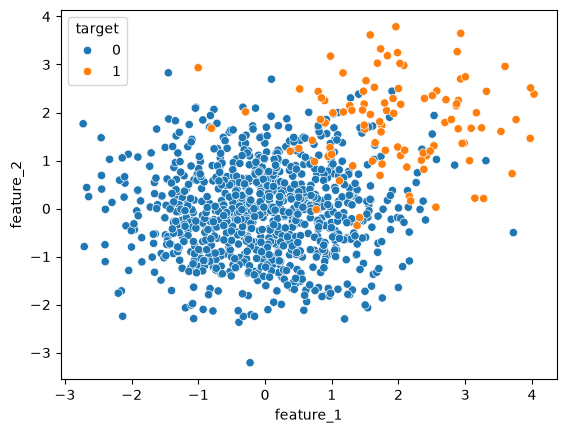

In [23]:
sns.scatterplot(data=df, x='feature_1', y='feature_2', hue='target')